# Moving Goal DQN

This notebook runs the moving-goal experiment alongside the original project. It does not modify any existing notebook or source file.

- The Goal moves one cell in one of the four cardinal directions every 3 steps.
- The DQN architecture and 24-dimensional observation remain unchanged.
- All outputs are saved in `results_moving_goal/`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root even when Jupyter starts in the notebooks/ folder.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "src" / "navigation_rl").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing src/navigation_rl")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from navigation_rl.environment import ACTION_NAMES
from navigation_rl.dqn import DQNAgent, DQNConfig, TrainingConfig, train_agent, plot_training_history
from moving_goal_dqn.environment import MovingGoalNavigationGridWorld
from moving_goal_dqn.evaluation import evaluate_moving_goal_policy

DEVICE = "cuda" if __import__("torch").cuda.is_available() else "cpu"
print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)

Project root: C:\Users\mhmd\Desktop\ML\1403\Notebooks\RL\03_01
Device: cpu


## 1. Inspect Goal Motion Before Training

The Agent takes several downward actions to avoid accidentally reaching the Goal during this demonstration. The Goal should move on step 3 and then once every 3 steps.

Agent: (0, 0) Initial Goal: (0, 6)
step=01 | agent=(1, 0) | goal=(0, 6) | goal_moved=False | reward=-0.515
step=02 | agent=(2, 0) | goal=(0, 6) | goal_moved=False | reward=-0.510
step=03 | agent=(3, 0) | goal=(0, 7) | goal_moved=True | reward=-1.000
step=04 | agent=(4, 0) | goal=(0, 7) | goal_moved=False | reward=-0.495
step=05 | agent=(5, 0) | goal=(0, 7) | goal_moved=False | reward=-0.490
step=06 | agent=(6, 0) | goal=(0, 6) | goal_moved=True | reward=0.010


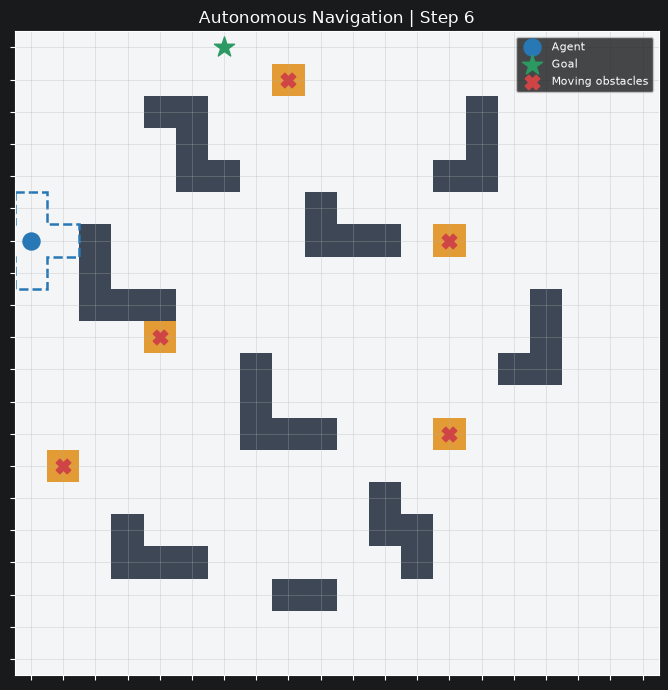

In [2]:
GOAL_MOVE_INTERVAL = 3
MAX_STEPS = 300

demo_env = MovingGoalNavigationGridWorld(
    max_steps=MAX_STEPS, goal_move_interval=GOAL_MOVE_INTERVAL
)
obs, reset_info = demo_env.reset(seed=123)
print("Agent:", demo_env.agent_pos, "Initial Goal:", demo_env.goal_pos)

for action in [1, 1, 1, 1, 1, 1]:  # DOWN
    obs, reward, terminated, truncated, info = demo_env.step(action)
    print(
        f"step={info['steps']:02d} | agent={info['agent_position']} | "
        f"goal={info['goal_position']} | goal_moved={info['goal_moved']} | "
        f"reward={reward:.3f}"
    )
    if terminated or truncated:
        break

demo_env.render(show_sensor=True)
plt.show()

## 2. Experiment Configuration

For a fair comparison, this notebook reuses the original DQN configuration without changing the network architecture or hyperparameters. Keep the episode count and step limit aligned with the baseline experiment you want to compare against.

In [9]:
SEED = 42
NUM_EPISODES = 1_000
NUM_EVAL_EPISODES = 200
MAX_STEPS = 500
VIDEO_EPISODES = [episode for episode in (1, 10, 50, 100, 200, 500, 1_000) if episode <= NUM_EPISODES]
GOAL_MOVE_INTERVAL = 3
OUTPUT_DIR = PROJECT_ROOT / "results_moving_goal"

DQN_CONFIG = DQNConfig(device=DEVICE)
TRAIN_CONFIG = TrainingConfig(
    episodes=NUM_EPISODES,
    seed=SEED,
    evaluation_episodes=NUM_EVAL_EPISODES,
    evaluation_seed=50_000,
    max_steps=MAX_STEPS,
    log_interval=20,
    checkpoint_interval=0,
    output_dir=str(OUTPUT_DIR),
    show_progress=True,
)

agent = DQNAgent(DQN_CONFIG, seed=SEED)
env = MovingGoalNavigationGridWorld(
    gamma=DQN_CONFIG.gamma,
    max_steps=MAX_STEPS,
    goal_move_interval=GOAL_MOVE_INTERVAL,
)

print("Observation dimension:", DQN_CONFIG.observation_dim)
print("Number of actions:", DQN_CONFIG.num_actions)
print("Goal movement interval:", GOAL_MOVE_INTERVAL)
print("Output directory:", OUTPUT_DIR)

Observation dimension: 24
Number of actions: 4
Goal movement interval: 3
Output directory: C:\Users\mhmd\Desktop\ML\1403\Notebooks\RL\03_01\results_moving_goal


## 3. Train a New DQN from Scratch

This cell uses the original project's `train_agent` function with the new moving-goal environment.

In [10]:
history = train_agent(agent, env, TRAIN_CONFIG, record_episodes=VIDEO_EPISODES)
print("Training finished.")
print("Episodes:", len(history))
print("Last-100 success rate:", history["success"].tail(100).mean())

DQN training:   0%|          | 0/1000 [00:00<?, ?episode/s]

Training finished.
Episodes: 1000
Last-100 success rate: 1.0


## 4. Greedy Evaluation

Epsilon exploration is disabled during evaluation. No learning or weight updates occur.

In [11]:
evaluation = evaluate_moving_goal_policy(
    agent,
    num_episodes=NUM_EVAL_EPISODES,
    seed=TRAIN_CONFIG.evaluation_seed,
    max_steps=MAX_STEPS,
    goal_move_interval=GOAL_MOVE_INTERVAL,
)
evaluation_table = pd.DataFrame([evaluation], index=["Moving-goal DQN"])
display(evaluation_table.round(4))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
evaluation_table.to_csv(OUTPUT_DIR / "evaluation_moving_goal.csv")
agent.save(
    OUTPUT_DIR / "dqn_moving_goal_final.pt",
    extra={
        "scenario": "moving_goal_random_walk",
        "goal_move_interval": GOAL_MOVE_INTERVAL,
        "max_steps": MAX_STEPS,
        "episodes": NUM_EPISODES,
    },
)

,success_rate,average_return,average_steps,blocked_action_rate,average_goal_moves
Moving-goal DQN,1.0,29.7964,21.11,0.0,6.275


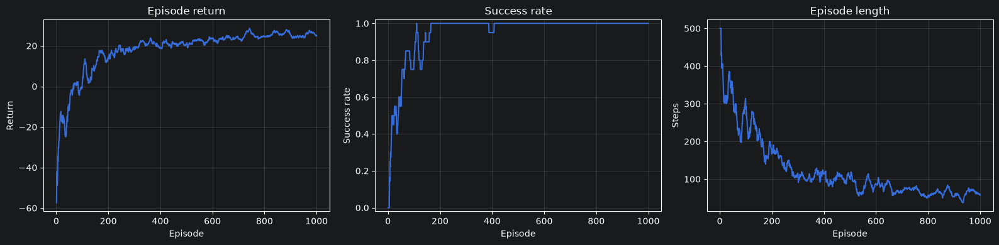

In [12]:
fig = plot_training_history(history, window=20)
plt.show()
fig.savefig(OUTPUT_DIR / "training_curves_moving_goal.png", dpi=160, bbox_inches="tight")

## 5. Recorded Training Episode Videos

These videos replay the exact states captured during the selected moving-goal **training episodes**. The Agent, moving Goal, and moving obstacles are updated from the real environment state at every recorded step. GIF is always generated; MP4 is also saved when FFmpeg is available.

Change `VIDEO_EPISODES` in the experiment configuration cell to select other episode numbers. If you change the selection, rerun the training cell so those episodes are recorded.

Episode 1 | success=False | steps=500
FFmpeg was not found; displaying the animated GIF instead.


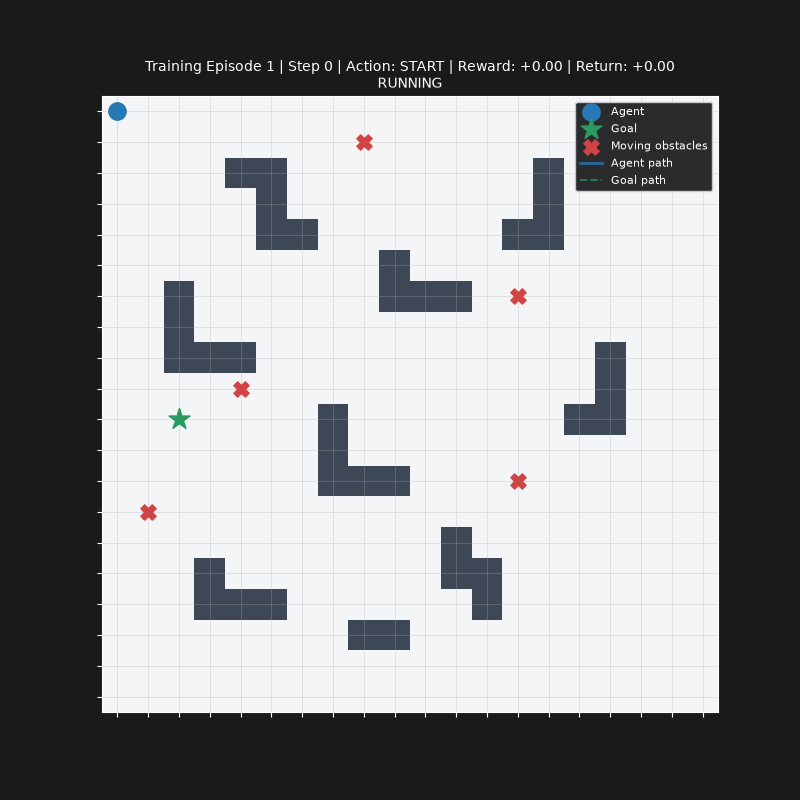

Episode 10 | success=True | steps=305
FFmpeg was not found; displaying the animated GIF instead.


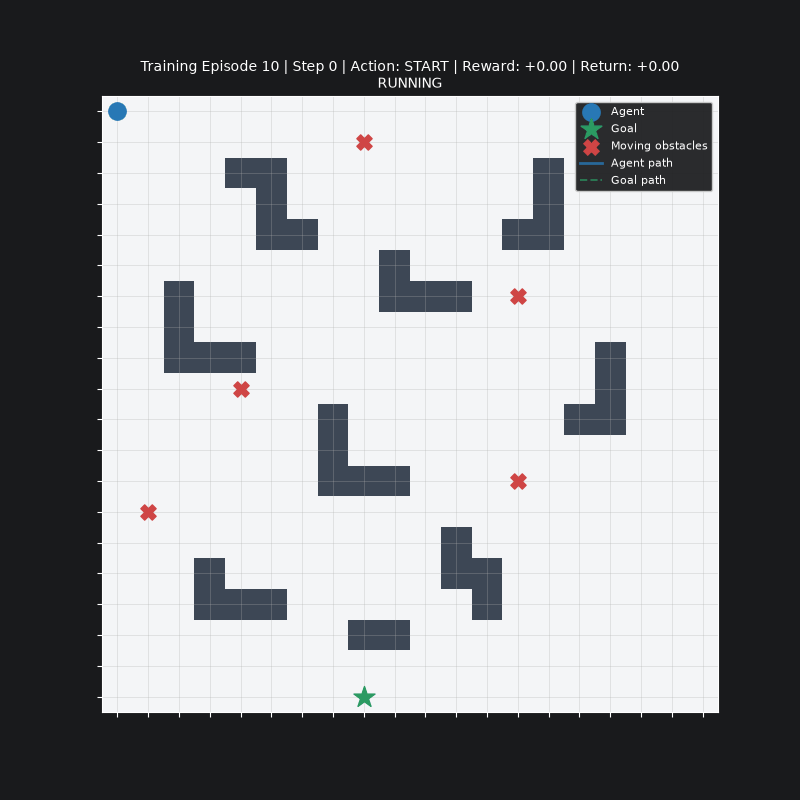

Episode 50 | success=False | steps=500
FFmpeg was not found; displaying the animated GIF instead.


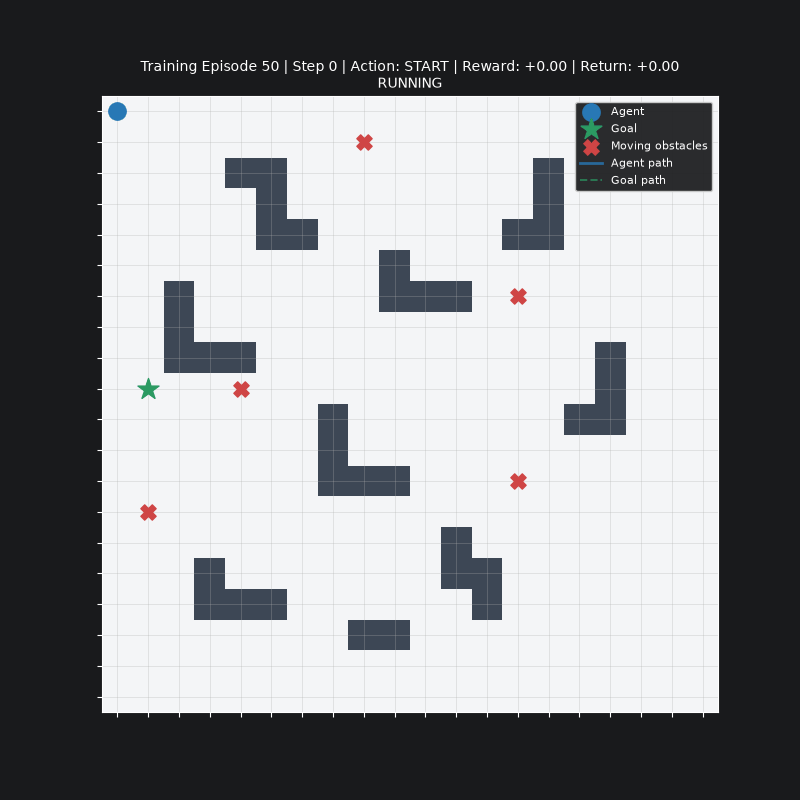

Episode 100 | success=True | steps=52
FFmpeg was not found; displaying the animated GIF instead.


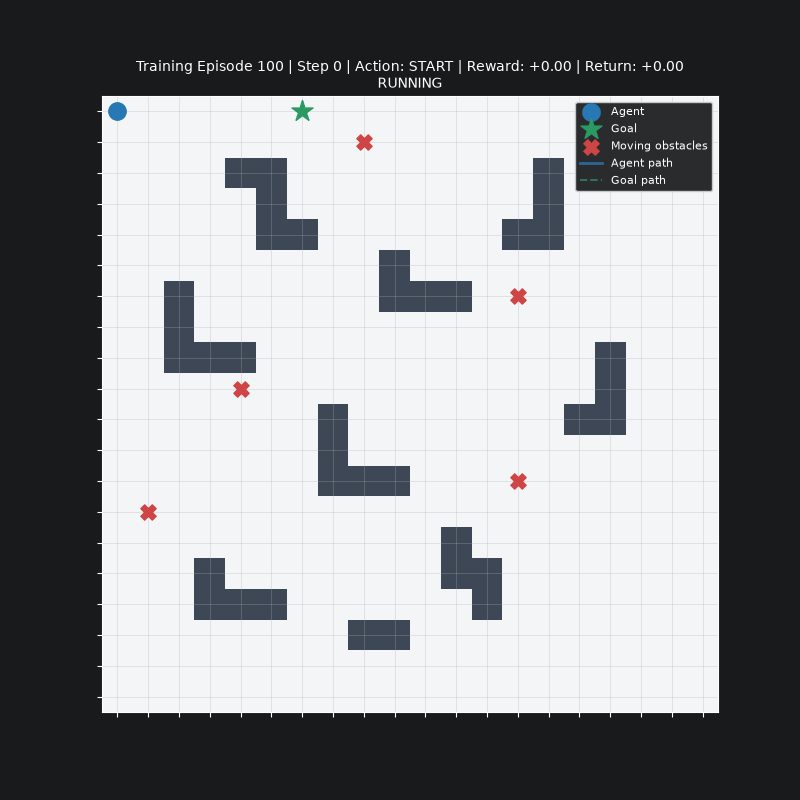

Episode 200 | success=True | steps=172
FFmpeg was not found; displaying the animated GIF instead.


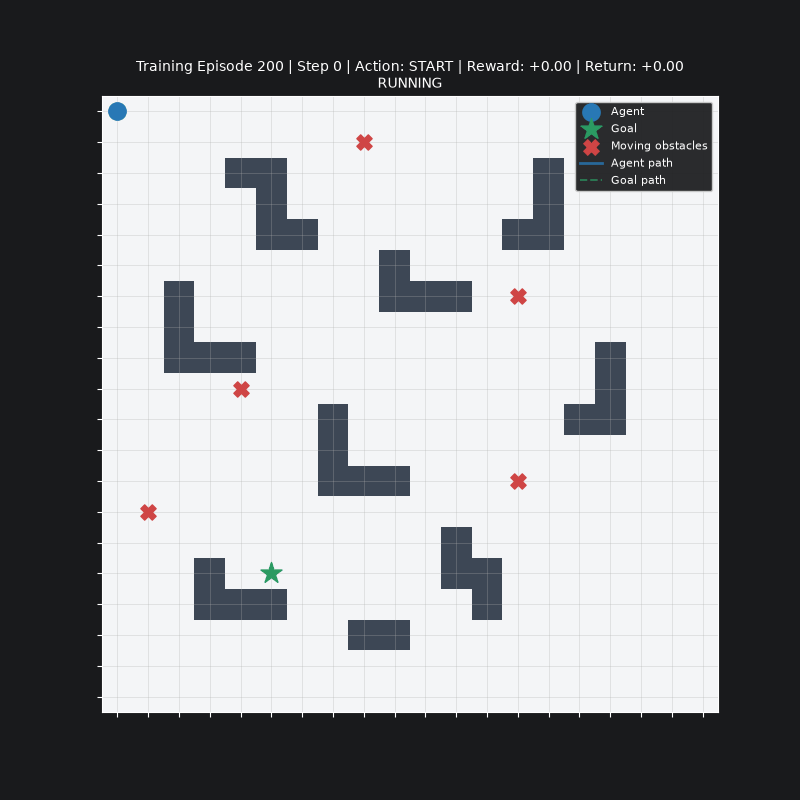

Episode 500 | success=True | steps=111
FFmpeg was not found; displaying the animated GIF instead.


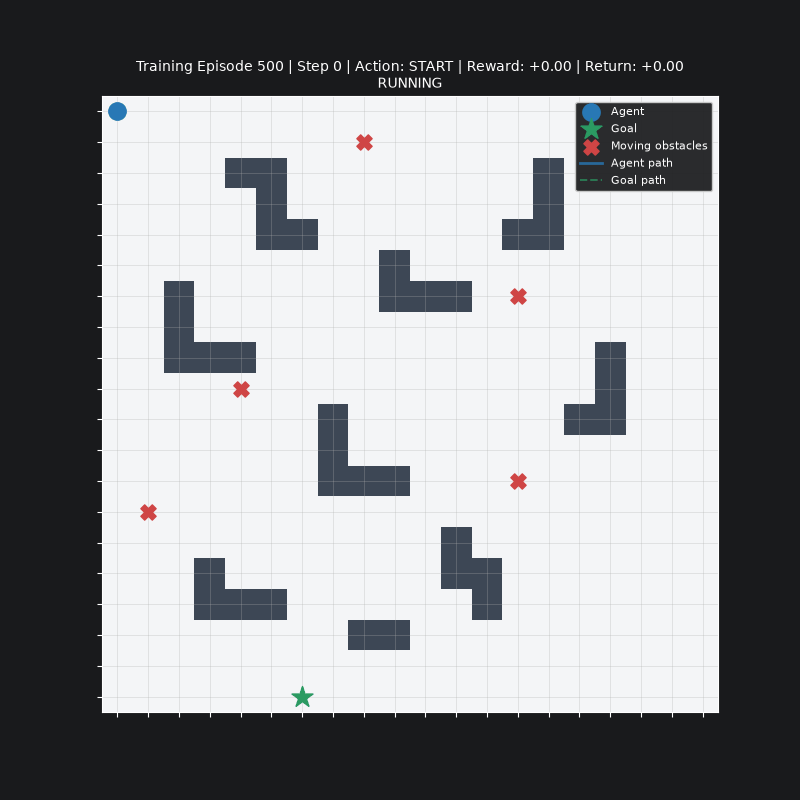

Episode 1000 | success=True | steps=77
FFmpeg was not found; displaying the animated GIF instead.


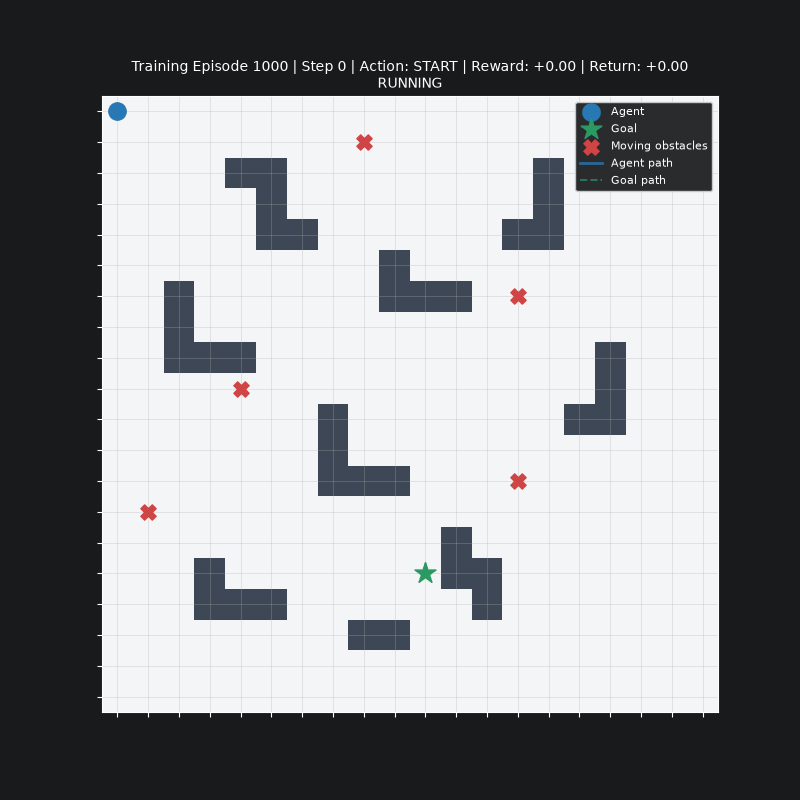

In [13]:
from IPython.display import Image, Video, display
from navigation_rl.episode_video import render_episode_videos

video_results = render_episode_videos(
    episode_dir=OUTPUT_DIR / "episodes",
    episodes=VIDEO_EPISODES,
    output_dir=OUTPUT_DIR / "videos",
    fps=10,
    save_mp4=True,
)

for video_result in video_results:
    print(
        f"Episode {video_result['episode']} | "
        f"success={video_result['success']} | steps={video_result['steps']}"
    )
    if video_result["mp4_path"]:
        display(Video(filename=video_result["mp4_path"], embed=True))
    else:
        print("FFmpeg was not found; displaying the animated GIF instead.")
        display(Image(filename=video_result["gif_path"]))


## 5. Optional: Evaluate the Existing Fixed-Goal Model Without Retraining

This check measures how well the DQN trained for a fixed Goal performs on the moving-goal task without changing its weights. Update the checkpoint path if your file is stored elsewhere.

In [14]:
BASELINE_CHECKPOINT = PROJECT_ROOT / "results" / "dqn_final.pt"
if BASELINE_CHECKPOINT.is_file():
    baseline_agent = DQNAgent.load(BASELINE_CHECKPOINT, map_location="cpu")
    baseline_moving_goal_eval = evaluate_moving_goal_policy(
        baseline_agent,
        num_episodes=NUM_EVAL_EPISODES,
        seed=TRAIN_CONFIG.evaluation_seed,
        max_steps=MAX_STEPS,
        goal_move_interval=GOAL_MOVE_INTERVAL,
    )
    display(pd.DataFrame([baseline_moving_goal_eval], index=["Old fixed-goal DQN (zero-shot)"]))
else:
    print("Baseline checkpoint not found; skipped zero-shot evaluation:", BASELINE_CHECKPOINT)

,success_rate,average_return,average_steps,blocked_action_rate,average_goal_moves
Old fixed-goal DQN (zero-shot),1.0,29.767925,21.76,0.0,6.525


## Result Interpretation

- `success_rate`: Fraction of episodes in which the Agent reaches the current Goal before the time limit.
- `average_steps`: Number of steps until success or timeout.
- `blocked_action_rate`: Fraction of actions that attempted to enter an occupied or invalid cell.
- `average_goal_moves`: Mean number of Goal movements per episode.

A 200-episode run is suitable as an initial pilot and debugging check. Research conclusions require a larger training budget and evaluation across multiple independent random seeds.